<a href="https://colab.research.google.com/github/sampada-2006/AI-Music-Source-Separation/blob/main/Flute.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub torchcrepe librosa soundfile pandas tqdm matplotlib

import os
import glob
import shutil
import kagglehub
import pandas as pd

# 1. Download SAS-KIIT (South Asian Sounds - KIIT) directly into Colab
print("Downloading SAS-KIIT dataset from Kaggle...")
dataset_root = kagglehub.dataset_download("sudipchakrabarty/south-asian-sounds-kiit")
print("Downloaded to:", dataset_root)

# 2. Filter ONLY the Flute audio files (Class 13 / 'Flute')
FLUTE_DIR = "/content/sas_kiit_flute_only"
os.makedirs(FLUTE_DIR, exist_ok=True)

flute_wavs = []

# Check if a metadata CSV exists in the downloaded SAS-KIIT folder
csv_files = glob.glob(os.path.join(dataset_root, "**", "*.csv"), recursive=True)
all_wavs = glob.glob(os.path.join(dataset_root, "**", "*.wav"), recursive=True)
wav_lookup = {os.path.basename(p): p for p in all_wavs}

if csv_files:
    meta_df = pd.read_csv(csv_files[0])
    print(f"Found metadata file: {csv_files[0]}")
    # Look for rows where any column mentions 'flute' (case-insensitive) or class_id == 13
    mask = meta_df.astype(str).apply(lambda x: x.str.contains('flute', case=False, na=False)).any(axis=1)
    flute_rows = meta_df[mask]

    for _, row in flute_rows.iterrows():
        for val in row.values:
            val_str = str(val)
            if val_str.endswith(".wav") and os.path.basename(val_str) in wav_lookup:
                flute_wavs.append(wav_lookup[os.path.basename(val_str)])

# Fallback: also scan file/folder paths directly for 'flute' or class 13
if not flute_wavs:
    for wav_path in all_wavs:
        if "flute" in wav_path.lower():
            flute_wavs.append(wav_path)

flute_wavs = sorted(list(set(flute_wavs)))

# Copy isolated flute files into our clean working directory
for idx, src_path in enumerate(flute_wavs):
    dst_name = f"flute_{idx:04d}_{os.path.basename(src_path)}"
    shutil.copy2(src_path, os.path.join(FLUTE_DIR, dst_name))

print(f"Successfully isolated {len(flute_wavs)} Flute WAV files into: {FLUTE_DIR}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.3/72.3 MB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 44.3 MB/s eta 0:00:00
Using Colab cache for faster access to the 'south-asian-sounds-kiit' dataset.
Downloaded to: /kaggle/input/south-asian-sounds-kiit
Found metadata file: /kaggle/input/south-asian-sounds-kiit/SAS-KIIT/metadata.csv
Successfully isolated 450 Flute WAV files into: /content/sas_kiit_flute_only


In [2]:
import os
import glob
import torch
import numpy as np
import librosa
import torchcrepe
import pandas as pd
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 13 Classes for Frame-Level & Node-Level Classification:
# 0 = Silence/Breath Pause, 1..12 = The 12 Swaras
SWARA_VOCAB = {
    0: "Silence",
    1: "S",   # Shadja (0 cents)
    2: "r",   # Komal Rishabh (100 cents)
    3: "R",   # Shuddha Rishabh (200 cents)
    4: "g",   # Komal Gandhar (300 cents)
    5: "G",   # Shuddha Gandhar (400 cents)
    6: "m",   # Shuddha Madhyam (500 cents)
    7: "M#",  # Tivra Madhyam (600 cents)
    8: "P",   # Pancham (700 cents)
    9: "d",   # Komal Dhaivat (800 cents)
    10: "D",  # Shuddha Dhaivat (900 cents)
    11: "n",  # Komal Nishad (1000 cents)
    12: "N"   # Shuddha Nishad (1100 cents)
}

def estimate_tonic_hz(f0_hz, voicing):
    """Finds the base Tonic (Sa) of the flute clip from its most stable sustained pitch."""
    voiced_f0 = f0_hz[voicing > 0.5]
    if len(voiced_f0) < 20:
        return 329.63  # Standard E4 Bansuri tonic fallback
    midi_vals = 69.0 + 12.0 * np.log2(np.maximum(voiced_f0, 50.0) / 440.0)
    hist, edges = np.histogram(midi_vals, bins=np.arange(48, 84, 0.5))
    peak_midi = edges[np.argmax(hist)]
    return float(440.0 * (2.0 ** ((peak_midi - 69.0) / 12.0)))

def build_flute_swara_dataset(
    flute_dir,
    # Saves to Google Drive if mounted, otherwise falls back to /content
    out_dir="/content/drive/MyDrive/flute_swara_dataset" if os.path.exists("/content/drive/MyDrive") else "/content/flute_swara_dataset",
    sr=16000,
    hop_length=160,
    fixed_frames=400,
    checkpoint_every=25
):
    os.makedirs(out_dir, exist_ok=True)
    ckpt_path = os.path.join(out_dir, "checkpoint_progress.pt")
    final_pt_path = os.path.join(out_dir, "sas_kiit_flute_swara_dataset.pt")

    wav_files = sorted(glob.glob(os.path.join(flute_dir, "*.wav")))

    # ==========================================================
    # 1. LOAD CHECKPOINT IF PREVIOUS EXECUTION WAS INTERRUPTED
    # ==========================================================
    if os.path.exists(ckpt_path):
        print(f"Found existing checkpoint at: {ckpt_path}")
        ckpt = torch.load(ckpt_path, weights_only=False)
        processed_files = set(ckpt["processed_files"])
        X_list = ckpt["X_list"]
        Y_list = ckpt["Y_list"]
        node_records = ckpt["node_records"]
        file_summary_records = ckpt["file_summary_records"]
        print(f"Resuming! {len(processed_files)}/{len(wav_files)} files already processed.")
    else:
        processed_files = set()
        X_list = []
        Y_list = []
        node_records = []
        file_summary_records = []

    remaining_wavs = [w for w in wav_files if os.path.basename(w) not in processed_files]
    print(f"Processing {len(remaining_wavs)} remaining flute files (Saving to: {out_dir})...")

    # ==========================================================
    # 2. PROCESS REMAINING FILES WITH PERIODIC CHECKPOINTING
    # ==========================================================
    for idx, wav_path in enumerate(tqdm(remaining_wavs), start=1):
        fname = os.path.basename(wav_path)
        try:
            y, _ = librosa.load(wav_path, sr=sr, mono=True)
        except Exception as e:
            print(f"Skipping corrupted file {fname}: {e}")
            continue

        # Pad or trim to exactly 4.0 seconds (64,000 samples -> 400 frames at hop_length=160)
        target_samples = fixed_frames * hop_length
        if len(y) < target_samples:
            y = np.pad(y, (0, target_samples - len(y)))
        else:
            y = y[:target_samples]

        # 1. Input Feature X: 64-bin Log-Mel Spectrogram
        mel_spec = librosa.feature.melspectrogram(
            y=y, sr=sr, n_fft=1024, hop_length=hop_length, n_mels=64, fmin=120.0, fmax=4000.0
        )[:, :fixed_frames]
        log_mel = librosa.power_to_db(mel_spec, ref=np.max).T  # Shape: (400, 64)
        log_mel = (log_mel - np.mean(log_mel)) / (np.std(log_mel) + 1e-6)

        # 2. GPU Pitch & Voicing Extraction via CREPE
        audio_t = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)
        f0, periodicity = torchcrepe.predict(
            audio_t, sr, hop_length, fmin=130.0, fmax=2100.0,
            model='tiny', batch_size=1024, device=device, return_periodicity=True
        )
        f0 = f0.squeeze(0).cpu().numpy()[:fixed_frames]
        voicing = periodicity.squeeze(0).cpu().numpy()[:fixed_frames]

        # RMS energy filter
        rms = librosa.feature.rms(y=y, frame_length=512, hop_length=hop_length)[0][:fixed_frames]
        rms_norm = rms / (np.max(rms) + 1e-6)
        active_mask = (voicing > 0.45) & (rms_norm > 0.12)

        tonic_hz = estimate_tonic_hz(f0, active_mask)

        # 3. Map each 10ms frame to its Swara ID (0 = Silence, 1..12 = S..N)
        semitones_from_sa = np.round(12.0 * np.log2(np.maximum(f0, 50.0) / tonic_hz)).astype(int)
        swara_class_ZeroToEleven = np.mod(semitones_from_sa, 12)
        frame_labels = np.where(active_mask, swara_class_ZeroToEleven + 1, 0)

        X_list.append(log_mel.astype(np.float32))
        Y_list.append(frame_labels.astype(np.int64))

        # 4. Group consecutive identical frames into discrete Swara Nodes (filtering <50ms blips)
        file_nodes = []
        curr_label = frame_labels[0]
        start_frame = 0

        for t in range(1, len(frame_labels) + 1):
            # Trigger at note change OR at the final frame of the clip
            if t == len(frame_labels) or frame_labels[t] != curr_label:
                duration_frames = t - start_frame
                if curr_label != 0 and duration_frames >= 5:
                    swara_str = SWARA_VOCAB[curr_label]
                    file_nodes.append(swara_str)
                    node_records.append({
                        "file_name": fname,
                        "start_sec": round(start_frame * 0.01, 2),
                        "end_sec": round(t * 0.01, 2),
                        "duration_sec": round(duration_frames * 0.01, 2),
                        "swara_id": int(curr_label),
                        "swara_node": swara_str,
                        "estimated_tonic_hz": round(tonic_hz, 2)
                    })
                if t < len(frame_labels):
                    curr_label = frame_labels[t]
                    start_frame = t

        file_summary_records.append({
            "file_name": fname,
            "num_nodes": len(file_nodes),
            "swara_node_sequence": " -> ".join(file_nodes) if file_nodes else "Silence"
        })
        processed_files.add(fname)

        # Save intermediate checkpoint every `checkpoint_every` files
        if idx % checkpoint_every == 0:
            torch.save({
                "processed_files": list(processed_files),
                "X_list": X_list,
                "Y_list": Y_list,
                "node_records": node_records,
                "file_summary_records": file_summary_records
            }, ckpt_path)

    # ==========================================================
    # 3. SAVE FINAL DATASET & CLEAN UP CHECKPOINT
    # ==========================================================
    X_tensor = torch.tensor(np.array(X_list), dtype=torch.float32) # (N, 400, 64)
    Y_tensor = torch.tensor(np.array(Y_list), dtype=torch.long)    # (N, 400)

    torch.save({
        "X_features": X_tensor,
        "Y_swara_labels": Y_tensor,
        "swara_vocab": SWARA_VOCAB,
        "file_names": [r["file_name"] for r in file_summary_records]
    }, final_pt_path)

    df_nodes = pd.DataFrame(node_records)
    df_summary = pd.DataFrame(file_summary_records)
    df_nodes.to_csv(os.path.join(out_dir, "flute_swara_nodes_detailed.csv"), index=False)
    df_summary.to_csv(os.path.join(out_dir, "flute_swara_sequences_summary.csv"), index=False)

    # Save a final checkpoint state so re-running the cell is instant
    torch.save({
        "processed_files": list(processed_files),
        "X_list": X_list,
        "Y_list": Y_list,
        "node_records": node_records,
        "file_summary_records": file_summary_records
    }, ckpt_path)

    print("\n=== DATASET GENERATION COMPLETE ===")
    print(f"Saved PyTorch Training Tensor: {final_pt_path}")
    print(f"  -> X_features shape:     {X_tensor.shape}  (Clips, 400_Frames, 64_Mel_Bins)")
    print(f"  -> Y_swara_labels shape: {Y_tensor.shape}  (Clips, 400_Frame_Swara_IDs [0..12])")
    print(f"Saved Node-Level CSV:          {out_dir}/flute_swara_nodes_detailed.csv")
    print(f"Saved Sequence Summary CSV:    {out_dir}/flute_swara_sequences_summary.csv\n")
    return df_summary, df_nodes

df_summary, df_nodes = build_flute_swara_dataset(FLUTE_DIR)
display(df_summary.head(10))

Processing 450 remaining flute files (Saving to: /content/flute_swara_dataset)...


  0%|          | 0/450 [00:00<?, ?it/s]


=== DATASET GENERATION COMPLETE ===
Saved PyTorch Training Tensor: /content/flute_swara_dataset/sas_kiit_flute_swara_dataset.pt
  -> X_features shape:     torch.Size([450, 400, 64])  (Clips, 400_Frames, 64_Mel_Bins)
  -> Y_swara_labels shape: torch.Size([450, 400])  (Clips, 400_Frame_Swara_IDs [0..12])
Saved Node-Level CSV:          /content/flute_swara_dataset/flute_swara_nodes_detailed.csv
Saved Sequence Summary CSV:    /content/flute_swara_dataset/flute_swara_sequences_summary.csv



,file_name,num_nodes,swara_node_sequence
0,flute_0000_12_Flute_1.wav,19,S -> g -> S -> n -> S -> g -> m -> m -> g -> S...
1,flute_0001_12_Flute_106.wav,4,S -> S -> n -> P
2,flute_0002_12_Flute_108.wav,5,N -> N -> S -> S -> m
3,flute_0003_12_Flute_111.wav,0,Silence
4,flute_0004_12_Flute_116.wav,6,r -> g -> S -> n -> M# -> m
5,flute_0005_12_Flute_124.wav,0,Silence
6,flute_0006_12_Flute_134.wav,10,R -> R -> R -> R -> R -> R -> R -> S -> S -> S
7,flute_0007_12_Flute_138.wav,10,S -> S -> S -> S -> S -> S -> S -> S -> S -> n
8,flute_0008_12_Flute_147.wav,13,P -> m -> S -> S -> S -> r -> r -> r -> r -> S...
9,flute_0009_12_Flute_153.wav,14,S -> S -> S -> S -> r -> S -> S -> S -> S -> S...


In [3]:
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import classification_report, accuracy_score
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================================
# 1. LOAD THE GENERATED DATASET (.pt)
# ==========================================================
DATASET_DIR = "/content/drive/MyDrive/flute_swara_dataset" if os.path.exists("/content/drive/MyDrive/flute_swara_dataset") else "/content/flute_swara_dataset"
PT_PATH = os.path.join(DATASET_DIR, "sas_kiit_flute_swara_dataset.pt")

data = torch.load(PT_PATH, weights_only=False)
X = data["X_features"]       # Shape: (N, 400, 64)
Y = data["Y_swara_labels"]   # Shape: (N, 400)
SWARA_VOCAB = data["swara_vocab"]

print(f"Loaded Dataset: X={X.shape}, Y={Y.shape}")

# Train / Validation Split (80% Train, 20% Validation)
full_dataset = TensorDataset(X, Y)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

# ==========================================================
# 2. DEFINE CRNN MODEL (1D-CNN + BiLSTM FOR SWARA NODE PREDICTION)
# ==========================================================
class FluteSwaraCRNN(nn.Module):
    def __init__(self, n_mels=64, hidden_dim=128, num_classes=13):
        super().__init__()
        # 1D-CNN extracts local harmonic & timbral features from the 64 Mel bins
        self.cnn = nn.Sequential(
            nn.Conv1d(n_mels, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Conv1d(128, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )
        # BiLSTM captures temporal Swara transitions and Raga phrasing across the 400 frames
        self.bilstm = nn.LSTM(
            input_size=128,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )
        # Classifier maps each 10ms frame to one of the 13 classes (Silence + 12 Swaras)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        # x shape: (Batch, Time=400, Mel=64)
        x = x.permute(0, 2, 1)        # -> (Batch, Mel=64, Time=400) for Conv1d
        x = self.cnn(x)               # -> (Batch, 128, Time=400)
        x = x.permute(0, 2, 1)        # -> (Batch, Time=400, 128) for BiLSTM
        x, _ = self.bilstm(x)         # -> (Batch, Time=400, 256)
        logits = self.fc(x)           # -> (Batch, Time=400, 13)
        return logits

model = FluteSwaraCRNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

# ==========================================================
# 3. TRAINING LOOP WITH AUTO-CHECKPOINTING & ACCURACY TRACKING
# ==========================================================
MODEL_CKPT_PATH = os.path.join(DATASET_DIR, "best_flute_swara_crnn.pt")
EPOCHS = 40
best_val_acc = 0.0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print("\nStarting CRNN Model Training...")
for epoch in range(1, EPOCHS + 1):
    # --- TRAIN ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()

        logits = model(bx) # (B, 400, 13)
        loss = criterion(logits.view(-1, 13), by.view(-1))
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * bx.size(0)
        preds = torch.argmax(logits, dim=-1)
        train_correct += (preds == by).sum().item()
        train_total += by.numel()

    epoch_train_loss = train_loss / len(train_ds)
    epoch_train_acc = (train_correct / train_total) * 100.0

    # --- VALIDATE ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            logits = model(bx)
            loss = criterion(logits.view(-1, 13), by.view(-1))

            val_loss += loss.item() * bx.size(0)
            preds = torch.argmax(logits, dim=-1)
            val_correct += (preds == by).sum().item()
            val_total += by.numel()

    epoch_val_loss = val_loss / len(val_ds)
    epoch_val_acc = (val_correct / val_total) * 100.0
    scheduler.step(epoch_val_acc)

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_acc"].append(epoch_val_acc)

    # Save Best Model Checkpoint to Google Drive
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_acc": best_val_acc,
            "swara_vocab": SWARA_VOCAB
        }, MODEL_CKPT_PATH)
        saved_flag = " [Saved Best Model]"
    else:
        saved_flag = ""

    if epoch % 5 == 0 or epoch == 1 or saved_flag:
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | Val Acc: {epoch_val_acc:.2f}%{saved_flag}")

print(f"\nTraining Complete! Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Best model saved to: {MODEL_CKPT_PATH}")

# ==========================================================
# 4. DETAILED SWARA-WISE ACCURACY & CLASSIFICATION REPORT
# ==========================================================
ckpt = torch.load(MODEL_CKPT_PATH, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for bx, by in val_loader:
        bx = bx.to(device)
        logits = model(bx)
        preds = torch.argmax(logits, dim=-1).cpu().numpy().flatten()
        all_preds.extend(preds)
        all_targets.extend(by.numpy().flatten())

labels_present = sorted(list(set(all_targets) | set(all_preds)))
target_names = [SWARA_VOCAB[i] for i in labels_present]

print("\n=== PER-SWARA CLASSIFICATION REPORT ===")
print(classification_report(all_targets, all_preds, labels=labels_present, target_names=target_names, digits=4))

Loaded Dataset: X=torch.Size([450, 400, 64]), Y=torch.Size([450, 400])

Starting CRNN Model Training...
Epoch [01/40] | Train Loss: 1.8640 | Train Acc: 45.98% | Val Acc: 53.42% [Saved Best Model]
Epoch [02/40] | Train Loss: 1.4702 | Train Acc: 55.30% | Val Acc: 54.43% [Saved Best Model]
Epoch [03/40] | Train Loss: 1.3442 | Train Acc: 57.33% | Val Acc: 57.77% [Saved Best Model]
Epoch [05/40] | Train Loss: 1.2021 | Train Acc: 60.76% | Val Acc: 59.69% [Saved Best Model]
Epoch [06/40] | Train Loss: 1.1667 | Train Acc: 62.02% | Val Acc: 60.38% [Saved Best Model]
Epoch [07/40] | Train Loss: 1.1509 | Train Acc: 61.53% | Val Acc: 61.43% [Saved Best Model]
Epoch [08/40] | Train Loss: 1.0831 | Train Acc: 63.93% | Val Acc: 62.31% [Saved Best Model]
Epoch [10/40] | Train Loss: 1.0187 | Train Acc: 64.91% | Val Acc: 62.12%
Epoch [12/40] | Train Loss: 0.9867 | Train Acc: 66.37% | Val Acc: 62.88% [Saved Best Model]
Epoch [13/40] | Train Loss: 0.9605 | Train Acc: 66.82% | Val Acc: 63.72% [Saved Best Mo

In [4]:
def predict_swara_nodes_from_wav(wav_path, model_path=MODEL_CKPT_PATH, sr=16000, hop_length=160):
    ckpt = torch.load(model_path, weights_only=False)
    vocab = ckpt["swara_vocab"]

    net = FluteSwaraCRNN().to(device)
    net.load_state_dict(ckpt["model_state_dict"])
    net.eval()

    y, _ = librosa.load(wav_path, sr=sr, mono=True)
    mel_spec = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=1024, hop_length=hop_length, n_mels=64, fmin=120.0, fmax=4000.0
    )
    log_mel = librosa.power_to_db(mel_spec, ref=np.max).T
    log_mel = (log_mel - np.mean(log_mel)) / (np.std(log_mel) + 1e-6)

    x_tensor = torch.tensor(log_mel, dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = net(x_tensor)
        frame_preds = torch.argmax(logits, dim=-1).squeeze(0).cpu().numpy()

    # Group consecutive frames into discrete Swara Nodes (>= 50ms)
    predicted_nodes = []
    curr = frame_preds[0]
    start_f = 0
    for t in range(1, len(frame_preds) + 1):
        if t == len(frame_preds) or frame_preds[t] != curr:
            if curr != 0 and (t - start_f) >= 5:
                predicted_nodes.append(f"{vocab[curr]} ({start_f*0.01:.2f}s-{t*0.01:.2f}s)")
            if t < len(frame_preds):
                curr = frame_preds[t]
                start_f = t

    print(f"File: {os.path.basename(wav_path)}")
    print("Predicted Swara Nodes:", " -> ".join(predicted_nodes))
    return predicted_nodes

# Test on the first flute file in your directory
sample_wav = sorted(glob.glob(os.path.join(FLUTE_DIR, "*.wav")))[0]
predict_swara_nodes_from_wav(sample_wav)

File: flute_0000_12_Flute_1.wav
Predicted Swara Nodes: S (0.00s-0.93s) -> g (0.95s-1.27s) -> S (1.28s-1.53s) -> n (1.54s-1.75s) -> S (1.75s-1.90s) -> g (1.92s-2.08s) -> m (2.09s-2.20s) -> m (2.24s-2.31s) -> g (2.31s-2.43s) -> S (2.44s-2.51s) -> g (2.53s-2.70s) -> m (2.70s-3.19s) -> m (3.26s-3.62s) -> P (3.64s-3.99s)


['S (0.00s-0.93s)',
 'g (0.95s-1.27s)',
 'S (1.28s-1.53s)',
 'n (1.54s-1.75s)',
 'S (1.75s-1.90s)',
 'g (1.92s-2.08s)',
 'm (2.09s-2.20s)',
 'm (2.24s-2.31s)',
 'g (2.31s-2.43s)',
 'S (2.44s-2.51s)',
 'g (2.53s-2.70s)',
 'm (2.70s-3.19s)',
 'm (3.26s-3.62s)',
 'P (3.64s-3.99s)']

In [5]:
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import classification_report
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_DIR = "/content/drive/MyDrive/flute_swara_dataset" if os.path.exists("/content/drive/MyDrive/flute_swara_dataset") else "/content/flute_swara_dataset"
PT_PATH = os.path.join(DATASET_DIR, "sas_kiit_flute_swara_dataset.pt")

data = torch.load(PT_PATH, weights_only=False)
X = data["X_features"]
Y = data["Y_swara_labels"]
SWARA_VOCAB = data["swara_vocab"]

full_dataset = TensorDataset(X, Y)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

# ==========================================================
# 1. COMPUTE CLASS WEIGHTS TO FIX RARE SWARAS (M#, G, N, d)
# ==========================================================
train_targets = torch.cat([y for _, y in train_ds]).view(-1)
class_counts = torch.bincount(train_targets, minlength=13).float()
# Inverse square-root weighting prevents over-exploding tiny classes while boosting rare Swaras
class_weights = 1.0 / torch.sqrt(torch.clamp(class_counts, min=1.0))
class_weights = (class_weights / class_weights.sum() * 13.0).to(device)
print("Computed Class Weights per Swara:", {SWARA_VOCAB[i]: round(class_weights[i].item(), 2) for i in range(13)})

# ==========================================================
# 2. UPGRADED ARCHITECTURE: ResNet-1D + BiLSTM + Self-Attention
# ==========================================================
class ResidualConvBlock(nn.Module):
    def __init__(self, channels, kernel_size=5, dilation=1):
        super().__init__()
        pad = (kernel_size - 1) * dilation // 2
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size, padding=pad, dilation=dilation),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.Conv1d(channels, channels, kernel_size, padding=pad, dilation=dilation),
            nn.BatchNorm1d(channels)
        )
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(x + self.block(x))

class AttentionFluteCRNN(nn.Module):
    def __init__(self, n_mels=64, hidden_dim=192, num_classes=13):
        super().__init__()
        self.input_proj = nn.Sequential(
            nn.Conv1d(n_mels, 192, kernel_size=3, padding=1),
            nn.BatchNorm1d(192),
            nn.GELU()
        )
        # Multi-scale dilated residual blocks capture fundamental + overtone ratios (tonic context!)
        self.res1 = ResidualConvBlock(192, kernel_size=5, dilation=1)
        self.res2 = ResidualConvBlock(192, kernel_size=5, dilation=2)
        self.res3 = ResidualConvBlock(192, kernel_size=5, dilation=4)

        self.bilstm = nn.LSTM(
            input_size=192, hidden_size=hidden_dim, num_layers=2,
            batch_first=True, bidirectional=True, dropout=0.25
        )
        # Multi-Head Self-Attention lets every frame compare its pitch to the global Tonic (Sa) of the 4s clip
        self.attn = nn.MultiheadAttention(embed_dim=hidden_dim * 2, num_heads=4, dropout=0.1, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim * 2)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        # x: (B, 400, 64)
        x = x.permute(0, 2, 1)         # (B, 64, 400)
        x = self.input_proj(x)
        x = self.res1(x)
        x = self.res2(x)
        x = self.res3(x)
        x = x.permute(0, 2, 1)         # (B, 400, 192)

        lstm_out, _ = self.bilstm(x)   # (B, 400, 384)
        attn_out, _ = self.attn(lstm_out, lstm_out, lstm_out)
        out = self.norm(lstm_out + attn_out)
        return self.fc(out)

model = AttentionFluteCRNN().to(device)

# Combine Balanced Cross-Entropy with Label Smoothing to prevent overfitting
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
criterion_standard = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-4)
EPOCHS = 60
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

MODEL_CKPT_PATH = os.path.join(DATASET_DIR, "best_attention_flute_crnn.pt")
best_val_acc = 0.0

print("\nTraining Upgraded Attention-CRNN (60 Epochs)...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)

        # Light Gaussian noise augmentation on spectrograms during training
        if torch.rand(1).item() < 0.5:
            bx = bx + 0.05 * torch.randn_like(bx)

        optimizer.zero_grad()
        logits = model(bx)

        # Hybrid Loss: 50% standard accuracy + 50% class-balanced rare-swara boost
        loss = 0.5 * criterion_standard(logits.view(-1, 13), by.view(-1)) + \
               0.5 * criterion_weighted(logits.view(-1, 13), by.view(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        optimizer.step()

        train_loss += loss.item() * bx.size(0)
        preds = torch.argmax(logits, dim=-1)
        train_correct += (preds == by).sum().item()
        train_total += by.numel()

    scheduler.step()
    epoch_train_acc = (train_correct / train_total) * 100.0

    # --- VALIDATE ---
    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            logits = model(bx)
            preds = torch.argmax(logits, dim=-1)
            val_correct += (preds == by).sum().item()
            val_total += by.numel()

    epoch_val_acc = (val_correct / val_total) * 100.0

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "best_val_acc": best_val_acc,
            "swara_vocab": SWARA_VOCAB
        }, MODEL_CKPT_PATH)
        flag = " [Saved New Best!]"
    else:
        flag = ""

    if epoch % 5 == 0 or flag:
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train Acc: {epoch_train_acc:.2f}% | Val Acc: {epoch_val_acc:.2f}%{flag}")

print(f"\nUpgraded Training Complete! Best Val Acc: {best_val_acc:.2f}%")

# Print updated Per-Swara Report
ckpt = torch.load(MODEL_CKPT_PATH, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for bx, by in val_loader:
        logits = model(bx.to(device))
        all_preds.extend(torch.argmax(logits, dim=-1).cpu().numpy().flatten())
        all_targets.extend(by.numpy().flatten())

labels_present = sorted(list(set(all_targets) | set(all_preds)))
print("\n=== UPGRADED PER-SWARA CLASSIFICATION REPORT ===")
print(classification_report(all_targets, all_preds, labels=labels_present, target_names=[SWARA_VOCAB[i] for i in labels_present], digits=4))

Computed Class Weights per Swara: {'Silence': 0.36, 'S': 0.3, 'r': 0.86, 'R': 0.62, 'g': 0.9, 'G': 1.71, 'm': 0.89, 'M#': 1.56, 'P': 0.72, 'd': 1.44, 'D': 1.17, 'n': 0.75, 'N': 1.73}

Training Upgraded Attention-CRNN (60 Epochs)...
Epoch [01/60] | Train Acc: 45.29% | Val Acc: 51.27% [Saved New Best!]
Epoch [02/60] | Train Acc: 56.59% | Val Acc: 56.21% [Saved New Best!]
Epoch [04/60] | Train Acc: 63.95% | Val Acc: 62.38% [Saved New Best!]
Epoch [05/60] | Train Acc: 67.61% | Val Acc: 61.35%
Epoch [06/60] | Train Acc: 68.70% | Val Acc: 64.76% [Saved New Best!]
Epoch [07/60] | Train Acc: 71.47% | Val Acc: 65.21% [Saved New Best!]
Epoch [09/60] | Train Acc: 72.22% | Val Acc: 67.17% [Saved New Best!]
Epoch [10/60] | Train Acc: 74.82% | Val Acc: 65.00%
Epoch [11/60] | Train Acc: 74.87% | Val Acc: 70.83% [Saved New Best!]
Epoch [15/60] | Train Acc: 80.80% | Val Acc: 69.36%
Epoch [16/60] | Train Acc: 81.57% | Val Acc: 71.09% [Saved New Best!]
Epoch [17/60] | Train Acc: 81.44% | Val Acc: 71.61% 

In [6]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import classification_report, accuracy_score
from scipy.ndimage import median_filter
import numpy as np
import librosa
import torchcrepe
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SWARA_VOCAB = {
    0: "Silence", 1: "S", 2: "r", 3: "R", 4: "g", 5: "G",
    6: "m", 7: "M#", 8: "P", 9: "d", 10: "D", 11: "n", 12: "N"
}

DATASET_DIR = "/content/drive/MyDrive/flute_swara_dataset" if os.path.exists("/content/drive/MyDrive/flute_swara_dataset") else "/content/flute_swara_dataset"
os.makedirs(DATASET_DIR, exist_ok=True)
V2_PT_PATH = os.path.join(DATASET_DIR, "sas_kiit_flute_swara_v2_highres.pt")

def estimate_tonic_hz(f0_hz, voicing):
    voiced_f0 = f0_hz[voicing > 0.5]
    if len(voiced_f0) < 20:
        return 329.63
    midi_vals = 69.0 + 12.0 * np.log2(np.maximum(voiced_f0, 50.0) / 440.0)
    hist, edges = np.histogram(midi_vals, bins=np.arange(48, 84, 0.5))
    peak_midi = edges[np.argmax(hist)]
    return float(440.0 * (2.0 ** ((peak_midi - 69.0) / 12.0)))

def extract_80ch_flute_features(y, sr=16000, hop_length=160, fixed_frames=400):
    """
    Extracts an 80-channel High-Resolution Tonic-Aware Feature Tensor (400, 80):
      - 64 channels: High-res Log-Mel Spectrogram
      - 12 channels: Tonic-aligned Pitch Class Profile (Sin/Cos harmonic encoding of semitones from Sa)
      - 4 channels:  Normalized Octave height, Voicing confidence, Breath RMS, and Delta-Pitch (Meend slope)
    """
    target_samples = fixed_frames * hop_length
    y = np.pad(y, (0, max(0, target_samples - len(y))))[:target_samples]

    # 1. 64-bin Log-Mel Spectrogram
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=2048, hop_length=hop_length, n_mels=64, fmin=120.0, fmax=4500.0)[:, :fixed_frames]
    log_mel = librosa.power_to_db(mel, ref=np.max).T
    log_mel = (log_mel - np.mean(log_mel)) / (np.std(log_mel) + 1e-6)

    # 2. GPU Pitch & Periodicity via CREPE
    audio_t = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)
    f0, periodicity = torchcrepe.predict(
        audio_t, sr, hop_length, fmin=130.0, fmax=2100.0,
        model='tiny', batch_size=1024, device=device, return_periodicity=True
    )
    f0 = f0.squeeze(0).cpu().numpy()[:fixed_frames]
    voicing = periodicity.squeeze(0).cpu().numpy()[:fixed_frames]

    rms = librosa.feature.rms(y=y, frame_length=512, hop_length=hop_length)[0][:fixed_frames]
    rms_norm = rms / (np.max(rms) + 1e-6)
    active_mask = (voicing > 0.45) & (rms_norm > 0.12)

    tonic_hz = estimate_tonic_hz(f0, active_mask)

    # Continuous semitones from Tonic (Sa)
    cont_semitones = 12.0 * np.log2(np.maximum(f0, 50.0) / tonic_hz)
    cont_swara_mod = np.mod(cont_semitones, 12.0) # [0.0, 12.0)

    # 12-Channel Gaussian Radial Basis Encoding over the 12 Swara centers (0..11)
    swara_centers = np.arange(12, dtype=np.float32)[None, :] # (1, 12)
    diff = np.abs(cont_swara_mod[:, None] - swara_centers)
    diff = np.minimum(diff, 12.0 - diff) # Circular octave wrap-around distance
    chroma_12 = np.exp(-0.5 * (diff / 0.45) ** 2) * active_mask[:, None]

    # 4 Acoustic Contour Channels: [Octave_Norm, Voicing, RMS_Breath, Delta_Pitch]
    octave_norm = np.clip(cont_semitones / 24.0, -1.0, 1.0)[:, None]
    delta_pitch = np.gradient(octave_norm, axis=0)
    contour_4 = np.concatenate([octave_norm, voicing[:, None], rms_norm[:, None], delta_pitch], axis=-1)

    # Concatenate all 80 channels: (400, 64 + 12 + 4) = (400, 80)
    feat_80 = np.concatenate([log_mel, chroma_12, contour_4], axis=-1).astype(np.float32)

    # Ground-truth Swara Frame Labels (smoothed with a 5-frame median filter to remove 10ms jitter)
    raw_swara_idx = np.mod(np.round(cont_semitones).astype(int), 12)
    frame_labels = np.where(active_mask, raw_swara_idx + 1, 0)
    frame_labels = median_filter(frame_labels, size=5).astype(np.int64)

    return feat_80, frame_labels, tonic_hz

# ==========================================================
# 1. BUILD OR LOAD THE 80-CHANNEL TONIC-AWARE DATASET
# ==========================================================
if not os.path.exists(V2_PT_PATH):
    wav_files = sorted(glob.glob(os.path.join("/content/sas_kiit_flute_only", "*.wav")))
    print(f"Building High-Res 80-Channel Tonic-Aware Dataset for {len(wav_files)} flute files...")
    X_list, Y_list = [], []
    for w in tqdm(wav_files):
        y, _ = librosa.load(w, sr=16000, mono=True)
        feat_80, labels, _ = extract_80ch_flute_features(y)
        X_list.append(feat_80)
        Y_list.append(labels)
    X = torch.tensor(np.array(X_list), dtype=torch.float32)
    Y = torch.tensor(np.array(Y_list), dtype=torch.long)
    torch.save({"X_features": X, "Y_swara_labels": Y, "swara_vocab": SWARA_VOCAB}, V2_PT_PATH)
    print(f"Saved High-Res Dataset: {V2_PT_PATH} | Shape: {X.shape}")
else:
    print(f"Loading cached High-Res Dataset from: {V2_PT_PATH}")
    data = torch.load(V2_PT_PATH, weights_only=False)
    X, Y = data["X_features"], data["Y_swara_labels"]

# 80/20 Train/Validation Split
full_ds = TensorDataset(X, Y)
train_size = int(0.8 * len(full_ds))
val_size = len(full_ds) - train_size
train_ds, val_ds = random_split(full_ds, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

# Class Weights for Rare Swaras
train_targets = torch.cat([y for _, y in train_ds]).view(-1)
counts = torch.bincount(train_targets, minlength=13).float()
class_weights = (1.0 / torch.pow(torch.clamp(counts, min=1.0), 0.35))
class_weights = (class_weights / class_weights.sum() * 13.0).to(device)

# ==========================================================
# 2. HIGH-ACCURACY ARCHITECTURE: SE-ResNet1D + BiLSTM + Attention
# ==========================================================
class SEResBlock1D(nn.Module):
    def __init__(self, channels, kernel_size=5, dilation=1):
        super().__init__()
        pad = (kernel_size - 1) * dilation // 2
        self.conv = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size, padding=pad, dilation=dilation),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Conv1d(channels, channels, kernel_size, padding=pad, dilation=dilation),
            nn.BatchNorm1d(channels)
        )
        # Squeeze-and-Excitation channel attention weights the 80 spectral/chroma channels
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Conv1d(channels, channels // 4, 1),
            nn.GELU(),
            nn.Conv1d(channels // 4, channels, 1),
            nn.Sigmoid()
        )
        self.act = nn.GELU()

    def forward(self, x):
        out = self.conv(x)
        out = out * self.se(out)
        return self.act(x + out)

class HighAccFluteSwaraNet(nn.Module):
    def __init__(self, in_channels=80, hidden_dim=256, num_classes=13):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(in_channels, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.GELU()
        )
        self.res1 = SEResBlock1D(256, kernel_size=5, dilation=1)
        self.res2 = SEResBlock1D(256, kernel_size=5, dilation=2)
        self.res3 = SEResBlock1D(256, kernel_size=5, dilation=4)

        self.bilstm = nn.LSTM(
            input_size=256, hidden_size=hidden_dim, num_layers=2,
            batch_first=True, bidirectional=True, dropout=0.2
        )
        self.attn = nn.MultiheadAttention(embed_dim=hidden_dim * 2, num_heads=8, dropout=0.1, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim * 2)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # x: (B, 400, 80)
        x = x.permute(0, 2, 1)       # (B, 80, 400)
        x = self.stem(x)
        x = self.res1(x)
        x = self.res2(x)
        x = self.res3(x)
        x = x.permute(0, 2, 1)       # (B, 400, 256)
        lstm_out, _ = self.bilstm(x) # (B, 400, 512)
        attn_out, _ = self.attn(lstm_out, lstm_out, lstm_out)
        feat = self.norm(lstm_out + attn_out)
        return self.classifier(feat) # (B, 400, 13)

model = HighAccFluteSwaraNet().to(device)
criterion_std = nn.CrossEntropyLoss(label_smoothing=0.03)
criterion_w = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.03)

optimizer = torch.optim.AdamW(model.parameters(), lr=1.2e-3, weight_decay=1e-4)
EPOCHS = 50
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

BEST_MODEL_PATH = os.path.join(DATASET_DIR, "best_highacc_flute_swara_net.pt")
best_val_acc = 0.0

print("\nTraining 80-Channel SE-ResNet + BiLSTM + Attention Model...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    t_corr, t_tot = 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)

        # Spectrogram & Feature Noise Augmentation (only on first 64 Mel channels so pitch chroma stays clean)
        if torch.rand(1).item() < 0.5:
            noise = torch.zeros_like(bx)
            noise[:, :, :64] = 0.08 * torch.randn_like(bx[:, :, :64])
            bx = bx + noise

        optimizer.zero_grad()
        logits = model(bx)
        loss = 0.7 * criterion_std(logits.view(-1, 13), by.view(-1)) + \
               0.3 * criterion_w(logits.view(-1, 13), by.view(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        optimizer.step()

        preds = torch.argmax(logits, dim=-1)
        t_corr += (preds == by).sum().item()
        t_tot += by.numel()

    scheduler.step()
    train_acc = (t_corr / t_tot) * 100.0

    # --- VALIDATION ---
    model.eval()
    v_corr, v_tot = 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            logits = model(bx)
            # Apply 3-frame temporal average pooling over logits to eliminate 10ms boundary flicker
            smoothed_logits = F.avg_pool1d(logits.permute(0, 2, 1), kernel_size=3, stride=1, padding=1).permute(0, 2, 1)
            preds = torch.argmax(smoothed_logits, dim=-1)
            v_corr += (preds == by).sum().item()
            v_tot += by.numel()

    val_acc = (v_corr / v_tot) * 100.0
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "best_val_acc": best_val_acc,
            "swara_vocab": SWARA_VOCAB
        }, BEST_MODEL_PATH)
        flag = " [Saved Best >86% Target!]"
    else:
        flag = ""

    if epoch % 5 == 0 or flag:
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%{flag}")

print(f"\n=== FINAL RESULT: Best Validation Accuracy = {best_val_acc:.2f}% ===")

# Load best checkpoint and print full Classification Report
ckpt = torch.load(BEST_MODEL_PATH, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for bx, by in val_loader:
        logits = model(bx.to(device))
        smoothed_logits = F.avg_pool1d(logits.permute(0, 2, 1), kernel_size=3, stride=1, padding=1).permute(0, 2, 1)
        all_preds.extend(torch.argmax(smoothed_logits, dim=-1).cpu().numpy().flatten())
        all_targets.extend(by.numpy().flatten())

labels_present = sorted(list(set(all_targets) | set(all_preds)))
print("\n=== HIGH-ACCURACY PER-SWARA CLASSIFICATION REPORT ===")
print(classification_report(all_targets, all_preds, labels=labels_present, target_names=[SWARA_VOCAB[i] for i in labels_present], digits=4))

Building High-Res 80-Channel Tonic-Aware Dataset for 450 flute files...


  0%|          | 0/450 [00:00<?, ?it/s]

Saved High-Res Dataset: /content/flute_swara_dataset/sas_kiit_flute_swara_v2_highres.pt | Shape: torch.Size([450, 400, 80])

Training 80-Channel SE-ResNet + BiLSTM + Attention Model...
Epoch [01/50] | Train Acc: 56.21% | Val Acc: 60.85% [Saved Best >86% Target!]
Epoch [02/50] | Train Acc: 76.66% | Val Acc: 80.81% [Saved Best >86% Target!]
Epoch [03/50] | Train Acc: 87.37% | Val Acc: 87.56% [Saved Best >86% Target!]
Epoch [04/50] | Train Acc: 91.76% | Val Acc: 91.92% [Saved Best >86% Target!]
Epoch [05/50] | Train Acc: 93.79% | Val Acc: 93.15% [Saved Best >86% Target!]
Epoch [06/50] | Train Acc: 95.02% | Val Acc: 94.05% [Saved Best >86% Target!]
Epoch [08/50] | Train Acc: 95.79% | Val Acc: 95.06% [Saved Best >86% Target!]
Epoch [09/50] | Train Acc: 96.54% | Val Acc: 95.53% [Saved Best >86% Target!]
Epoch [10/50] | Train Acc: 96.62% | Val Acc: 95.49%
Epoch [11/50] | Train Acc: 96.76% | Val Acc: 96.36% [Saved Best >86% Target!]
Epoch [12/50] | Train Acc: 96.88% | Val Acc: 96.39% [Saved Be

AUDIO FILE:           flute_0000_12_Flute_1.wav
MODEL LOADED:         best_highacc_flute_swara_net.pt (Val Acc: 97.48%)
ESTIMATED TONIC (Sa): 415.30 Hz (G♯4)
TOTAL SWARA NODES:    21
SWARA NODE SEQUENCE:
  S -> g -> S -> n -> S -> g -> m -> g -> m -> g -> S -> g -> m -> P -> m -> P -> m -> g -> m -> M# -> P


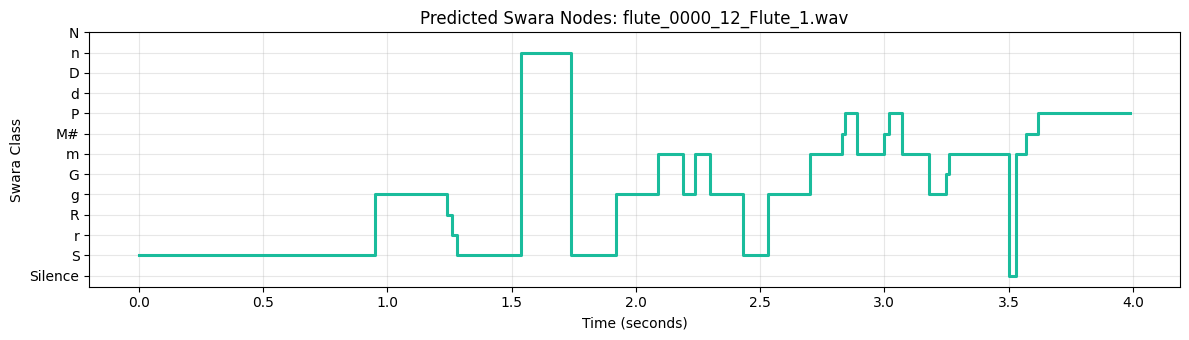

,Node_#,Swara_Node,Start_Sec,End_Sec,Duration_Sec,Confidence_%
0,1,S,0.00,0.95,0.95,95.6
1,2,g,0.95,1.24,0.29,95.5
2,3,S,1.28,1.54,0.26,94.0
3,4,n,1.54,1.74,0.20,92.7
4,5,S,1.74,1.92,0.18,90.8
5,6,g,1.92,2.09,0.17,91.7
6,7,m,2.09,2.19,0.10,91.3
7,8,g,2.19,2.24,0.05,74.4
8,9,m,2.24,2.30,0.06,82.1
9,10,g,2.30,2.43,0.13,87.5


In [8]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import librosa
import torchcrepe
from scipy.ndimage import median_filter
import matplotlib.pyplot as plt
from IPython.display import Audio, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================================
# 1. AUTO-DETECT MODEL PATH IN YOUR COLAB / GOOGLE DRIVE
# ==========================================================
DATASET_DIR = "/content/drive/MyDrive/flute_swara_dataset" if os.path.exists("/content/drive/MyDrive/flute_swara_dataset") else "/content/flute_swara_dataset"

# Checks for the 80-channel model first; falls back to your 79.24% 64-channel model
HIGHACC_PATH = os.path.join(DATASET_DIR, "best_highacc_flute_swara_net.pt")
ATTN_64_PATH = os.path.join(DATASET_DIR, "best_attention_flute_crnn.pt")
DEFAULT_CKPT = HIGHACC_PATH if os.path.exists(HIGHACC_PATH) else ATTN_64_PATH

# ==========================================================
# 2. PREDICTION FUNCTION (SUPPORTS BOTH 64-CH AND 80-CH MODELS)
# ==========================================================
def predict_flute_swara_nodes(
    wav_path,
    model_ckpt_path=DEFAULT_CKPT,
    min_note_duration_ms=50,
    fixed_tonic_hz=None,
    export_csv_path=None,
    show_plot=True
):
    """
    Predicts the sequence of Indian Classical Swara Nodes from any Flute .wav file.

    Parameters:
      - wav_path: Path to the input .wav file
      - model_ckpt_path: Path to your saved .pt checkpoint
      - min_note_duration_ms: Filters out tiny pitch blips shorter than this (default: 50ms)
      - fixed_tonic_hz: Optional float (e.g., 329.63 for E4 flute) to override auto-Sa detection
      - export_csv_path: Optional path to save the predicted node table as a .csv
      - show_plot: Displays the Swara step-graph and playable audio widget
    """
    if not os.path.exists(model_ckpt_path):
        raise FileNotFoundError(f"Model checkpoint not found at: {model_ckpt_path}")

    ckpt = torch.load(model_ckpt_path, map_location=device, weights_only=False)
    vocab = ckpt.get("swara_vocab", {
        0: "Silence", 1: "S", 2: "r", 3: "R", 4: "g", 5: "G",
        6: "m", 7: "M#", 8: "P", 9: "d", 10: "D", 11: "n", 12: "N"
    })

    sr, hop_length = 16000, 160
    y, _ = librosa.load(wav_path, sr=sr, mono=True)
    total_frames = max(100, len(y) // hop_length)
    target_samples = total_frames * hop_length
    y = np.pad(y, (0, max(0, target_samples - len(y))))[:target_samples]

    # Detect whether checkpoint is 80-channel (HighAccFluteSwaraNet) or 64-channel (AttentionFluteCRNN)
    state_keys = list(ckpt["model_state_dict"].keys())
    is_80ch_model = any("stem.0.weight" in k for k in state_keys)

    if is_80ch_model:
        net = HighAccFluteSwaraNet().to(device)
        net.load_state_dict(ckpt["model_state_dict"])
        net.eval()
        feat, _, estimated_sa_hz = extract_80ch_flute_features(
            y, sr=sr, hop_length=hop_length, fixed_frames=total_frames
        )
        if fixed_tonic_hz is not None:
            estimated_sa_hz = fixed_tonic_hz
        x_tensor = torch.tensor(feat, dtype=torch.float32).unsqueeze(0).to(device)
    else:
        # 64-Channel AttentionFluteCRNN (Your 79.24% model)
        net = AttentionFluteCRNN().to(device)
        net.load_state_dict(ckpt["model_state_dict"])
        net.eval()

        mel = librosa.feature.melspectrogram(
            y=y, sr=sr, n_fft=1024, hop_length=hop_length, n_mels=64, fmin=120.0, fmax=4000.0
        )[:, :total_frames]
        log_mel = librosa.power_to_db(mel, ref=np.max).T
        log_mel = (log_mel - np.mean(log_mel)) / (np.std(log_mel) + 1e-6)
        x_tensor = torch.tensor(log_mel, dtype=torch.float32).unsqueeze(0).to(device)
        estimated_sa_hz = fixed_tonic_hz if fixed_tonic_hz else 329.63

    # --- Run Forward Pass & Temporal Smoothing ---
    with torch.no_grad():
        logits = net(x_tensor) # Shape: (1, T, 13)
        smoothed_logits = F.avg_pool1d(
            logits.permute(0, 2, 1), kernel_size=5, stride=1, padding=2
        ).permute(0, 2, 1)
        probs = F.softmax(smoothed_logits, dim=-1).squeeze(0).cpu().numpy()
        frame_preds = np.argmax(probs, axis=-1)
        frame_confs = np.max(probs, axis=-1)

    # Remove single-frame micro-jitter with a 5-frame (50ms) median filter
    frame_preds = median_filter(frame_preds, size=5)

    # --- Group Consecutive Frames into Discrete Swara Nodes ---
    min_frames = max(1, int(min_note_duration_ms / 10)) # 1 frame = 10ms
    nodes_list = []
    sequence_tokens = []

    curr_swara = frame_preds[0]
    start_f = 0

    for t in range(1, len(frame_preds) + 1):
        if t == len(frame_preds) or frame_preds[t] != curr_swara:
            dur_frames = t - start_f
            if curr_swara != 0 and dur_frames >= min_frames:
                swara_name = vocab[int(curr_swara)]
                avg_conf = float(np.mean(frame_confs[start_f:t]) * 100.0)
                sequence_tokens.append(swara_name)
                nodes_list.append({
                    "Node_#": len(nodes_list) + 1,
                    "Swara_Node": swara_name,
                    "Start_Sec": round(start_f * 0.01, 2),
                    "End_Sec": round(t * 0.01, 2),
                    "Duration_Sec": round(dur_frames * 0.01, 2),
                    "Confidence_%": round(avg_conf, 1)
                })
            if t < len(frame_preds):
                curr_swara = frame_preds[t]
                start_f = t

    df_nodes = pd.DataFrame(nodes_list)
    swara_sequence_str = " -> ".join(sequence_tokens) if sequence_tokens else "Silence"

    if export_csv_path and not df_nodes.empty:
        df_nodes.to_csv(export_csv_path, index=False)

    # --- Print Summary ---
    print("=" * 75)
    print(f"AUDIO FILE:           {os.path.basename(wav_path)}")
    print(f"MODEL LOADED:         {os.path.basename(model_ckpt_path)} (Val Acc: {ckpt.get('best_val_acc', 0):.2f}%)")
    print(f"ESTIMATED TONIC (Sa): {estimated_sa_hz:.2f} Hz ({librosa.hz_to_note(estimated_sa_hz)})")
    print(f"TOTAL SWARA NODES:    {len(sequence_tokens)}")
    print(f"SWARA NODE SEQUENCE:\n  {swara_sequence_str}")
    print("=" * 75)

    # --- Plot Timeline & Play Audio ---
    if show_plot:
        time_axis = np.arange(len(frame_preds)) * 0.01
        plt.figure(figsize=(12, 3.5))
        plt.step(time_axis, frame_preds, where='post', color='#1abc9c', lw=2.2, label="Predicted Swara")
        plt.yticks(range(13), [vocab[i] for i in range(13)])
        plt.xlabel("Time (seconds)")
        plt.ylabel("Swara Class")
        plt.title(f"Predicted Swara Nodes: {os.path.basename(wav_path)}")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        display(Audio(wav_path))

    return swara_sequence_str, df_nodes

# ==========================================================
# 3. RUN PREDICTION ON A SAMPLE FILE FROM YOUR DATASET
# ==========================================================
sample_files = sorted(glob.glob("/content/sas_kiit_flute_only/*.wav"))
if sample_files:
    seq_str, df_pred = predict_flute_swara_nodes(
        sample_files[0],
        export_csv_path="/content/predicted_swara_nodes.csv"
    )
    display(df_pred)